In [1]:
# Broad Agenda
# 1. Experiment Tracking and Model Serving
# 2. ML Pipelines, Monitoring and Drift

In [2]:
# Detailed Agenda:

# 1. FDE Role, Customer Problem Statement & End-to-End MLOps Architecture

# 2. Environment Setup, ML Fundamentals & Building the First Prediction Model

# 3. MLflow Fundamentals, Experiment Tracking & Model Comparison

# 4. Model Registry, Model Serving & API Integration with FastAPI

# 5. ML Pipelines: Automating Training, Evaluation & Model Management

# 6. Production Monitoring, Model Performance & Data Quality Checks

# 7. Data Drift, Concept Drift & Performance Degradation Detection

# 8. Alerting, Feedback Loops, Model Maintenance & Retraining Decisions

# 9. End-to-End FDE Workflow, Production Readiness & Customer Handover

# 10. Questions & Answers

## Topic 1: FDE Role, Customer Problem Statement & End-to-End MLOps Architecture

In [3]:
# Topic 1: FDE Role, Customer Problem Statement & End-to-End MLOps Architecture

In [4]:
# Imagine you're working with a customer who tells you:
#     'We developed a machine learning model that was giving us 95% accuracy during testing. We deployed it into production, and three months later, its accuracy dropped to 80%.'

# Now, as an engineer responsible for this customer, what would you investigate first?
# => We'd investigate whether incoming data has changed, whether the evaluation is reliable, and whether something changed in the production environment. We would also examine the impact on the customer's business.

In [5]:
# What exactly is an FDE?

# FDE stands for Forward Deployed Engineer.
# For example, a traditional ML engineer may focus on building and improving a prediction model.
# An FDE goes beyond that. We ask: What problem is the customer solving? Where does the data come from? How will the solution integrate with existing systems? And most importantly, how will we know that it is delivering business value?

In [6]:
# Understanding the customer problem

# Let's take a retail customer like Walmart.

# The customer says, 'We want to predict product demand because we frequently experience stockouts.'

# This is a business problem, not yet a complete machine learning problem.

# As FDEs, we translate this into something measurable.

# For example: predict product demand for the next seven days, using historical sales data, with the objective of reducing forecast errors and improving product availability.

# Before starting development, we need clarity on three things: the business objective, the available data, and the success criteria.

# That becomes the foundation for our entire solution.

### End-to-End MLOps Architecture

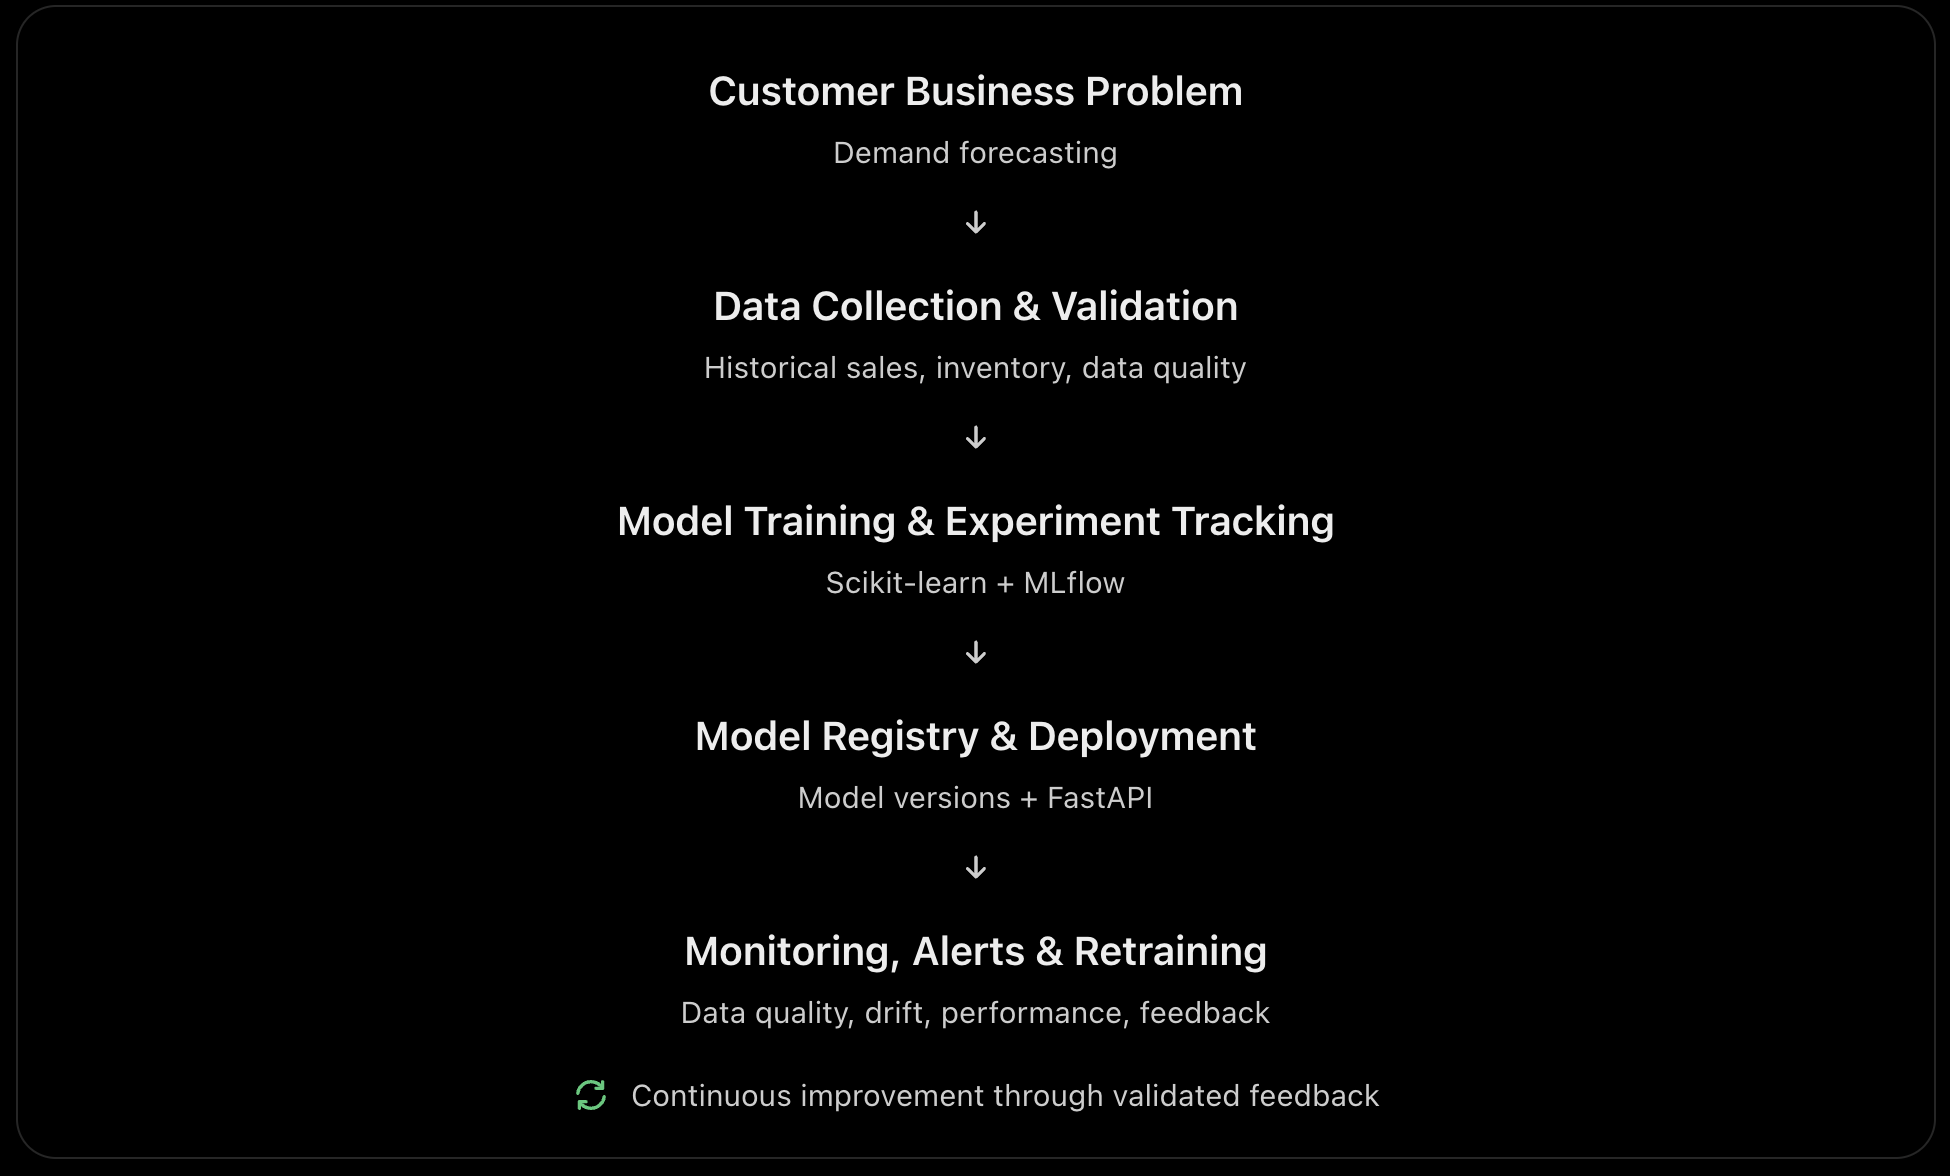

## Topic 2: Environment Setup, ML Fundamentals & Building the First Prediction Model

In [7]:
# Topic 2: Environment Setup, ML Fundamentals & Building the First Prediction Model

In [8]:
# Customer problem and ML fundamentals

# Imagine our retail customer wants to predict how many units of a product will be sold tomorrow.

# Historically, the store has been selling anywhere between 80 and 150 units per day, depending on the day of the week and whether there is a promotion.

# Our goal is to build a model that learns from historical sales and predicts future demand.
# This is called supervised machine learning, because we have historical input information as well as the actual sales quantities that the model should learn to predict.
# Since we're predicting a numerical quantity, this is a regression problem, not a classification problem.

In [9]:
# Environment setup

# Step A: Open the terminal
# MacOS:
# Verify Python:
# python3 --version
# Windows:
# py --version

# Create the project and virtual environment:
# MacOS:
# mkdir fde-mlops
# cd fde-mlops
# python3 -m venv .venv
# source .venv/bin/activate
# Windows:
# mkdir fde-mlops
# cd fde-mlops
# py -m venv .venv
# .\.venv\Scripts\Activate.ps1

# Install dependencies:
# MacOS:
# python -m pip install --upgrade pip
# python -m pip install numpy pandas scikit-learn joblib
# Windows:
# python -m pip install --upgrade pip
# python -m pip install numpy pandas scikit-learn joblib

In [10]:
# Understand our retail dataset

# Let's imagine we have historical sales data for one product across 240 days.

# For every day, we know the day of the week, whether a promotion was active, and how many units were sold.

# We'll also use the sales quantity from seven days earlier to help capture weekly purchasing patterns.

# In a real customer project, this information would come from systems such as ERP, POS, or a data warehouse.

# For today's demonstration, we'll generate realistic-looking synthetic data using Python. That means nobody needs to download or access confidential customer data.

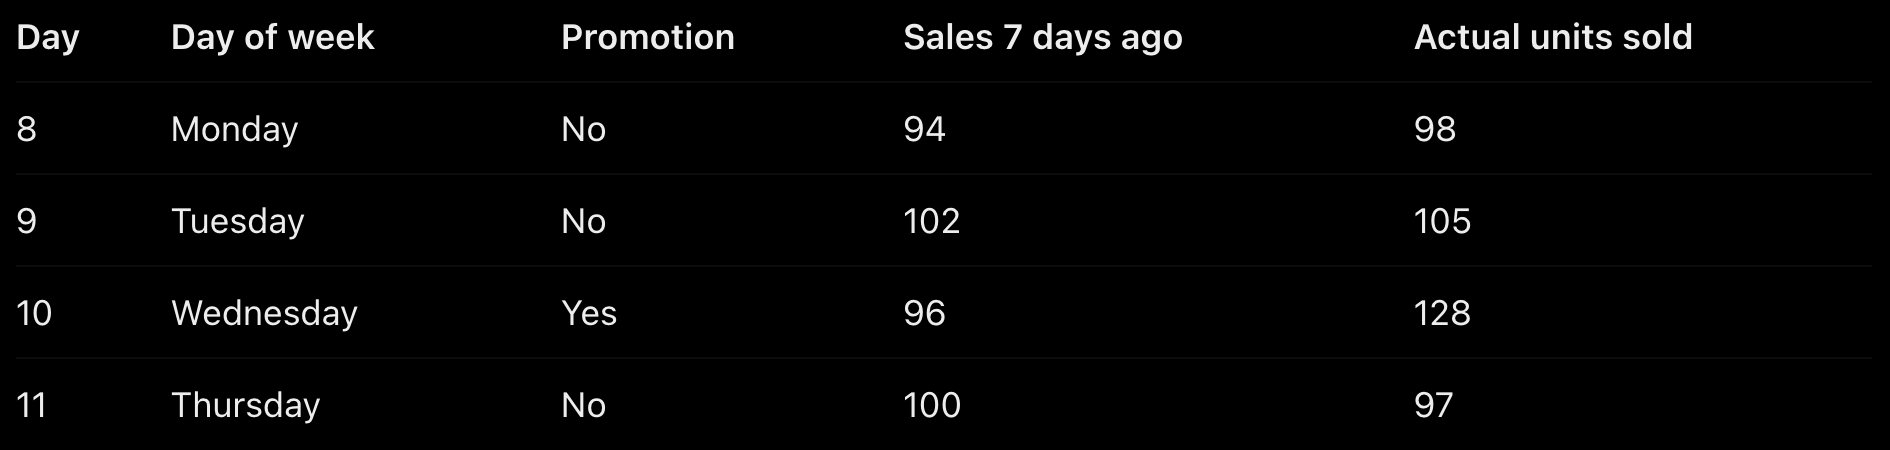

In [11]:
# Build the first prediction model

# Create a Python file named train.py in the fde-mlops folder.


# from pathlib import Path
# import numpy as np
# import pandas as pd
# import joblib

# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import mean_absolute_error

# # STEP 1: Generate 240 days of retail sales
# rng = np.random.default_rng(42)

# days = np.arange(1, 241)
# day_of_week = (days - 1) % 7
# promotion = ((days % 17) < 3).astype(int)

# sales = (
#     95
#     + 15 * (day_of_week >= 5)
#     + 30 * promotion
#     + rng.normal(0, 5, len(days))
# )

# sales = np.maximum(0, np.rint(sales)).astype(int)

# # STEP 2: Create a dataset
# df = pd.DataFrame({
#     "day": days,
#     "day_of_week": day_of_week,
#     "promotion": promotion,
#     "sales": sales
# })

# # STEP 3: Create a historical sales feature
# df["sales_lag_7"] = df["sales"].shift(7)
# df = df.dropna().copy()

# # STEP 4: Define model inputs and target
# features = [
#     "day_of_week",
#     "promotion",
#     "sales_lag_7"
# ]

# target = "sales"

# # STEP 5: Split chronologically
# train = df[df["day"] <= 200]
# test = df[df["day"] > 200]

# X_train = train[features]
# y_train = train[target]

# X_test = test[features]
# y_test = test[target]

# # STEP 6: Create the ML model
# model = RandomForestRegressor(
#     n_estimators=100,
#     max_depth=5,
#     random_state=42
# )

# # STEP 7: Train
# model.fit(X_train, y_train)

# # STEP 8: Predict on unseen dates
# predictions = model.predict(X_test)

# # STEP 9: Evaluate model performance
# mae = mean_absolute_error(
#     y_test,
#     predictions
# )

# print(f"Mean Absolute Error: {mae:.2f} units")

# # STEP 10: Display predictions
# results = pd.DataFrame({
#     "actual_sales": y_test.to_numpy(),
#     "predicted_sales": predictions.round(1)
# })

# print(results.head())

# # STEP 11: Save reusable project artifacts
# output = Path("artifacts")
# output.mkdir(exist_ok=True)

# joblib.dump(model, output / "demand_model.joblib")
# joblib.dump(features, output / "features.joblib")

# print("Model saved successfully!")


# Execute the file
# python train.py

In [12]:
# MCQ 1. In our retail demand model, which variable represents the target?
# a. Day of the week
# b. Promotion status
# >c. Actual units sold
# d. Number of decision trees

# MCQ 2. Our model achieves an MAE of 3.72. What does that mean?
# a. The model has 3.72% accuracy
# >b. The average absolute prediction error is 3.72 units
# c. Every prediction is incorrect by exactly 3.72 units
# d. The model is ready for production

## Topic 3: MLflow Fundamentals, Experiment Tracking & Model Comparison

In [13]:
# Topic 3: MLflow Fundamentals, Experiment Tracking & Model Comparison

In [14]:
# Why do we need MLflow?

# In our previous session, we successfully developed a machine learning model for retail demand forecasting.

# We used Random Forest, generated predictions, and measured model performance using Mean Absolute Error.

# Now imagine the customer asks us a very practical question:
#     'Can you improve the model's accuracy before we deploy it?'

# As engineers, we might try a hundred decision trees, two hundred trees, different tree depths, or even different algorithms.

# But here's the challenge.

# After running ten experiments, how do we remember which model used which parameters? Which model performed best? And how do we retrieve that model later?

# We could manually record everything in Excel, but that is inefficient and error-prone.
# This is exactly the problem MLflow solves.

# MLflow helps us systematically record, organize, compare, and manage machine learning experiments.

# Today, instead of training only one model, we'll train three versions of our existing model and compare them in the MLflow dashboard.

In [15]:
# MLflow fundamental concepts

# Let's understand five terms.

# An experiment is a collection of related training attempts.

# A run is one execution of our training process.

# Parameters are the settings we choose before training, such as number of trees or maximum tree depth.

# Metrics are the results we calculate after training, such as Mean Absolute Error.

# And artifacts are saved outputs, such as trained models, charts, or reports.

# So one experiment can contain multiple runs, and each run records its own parameters, metrics, and artifacts.

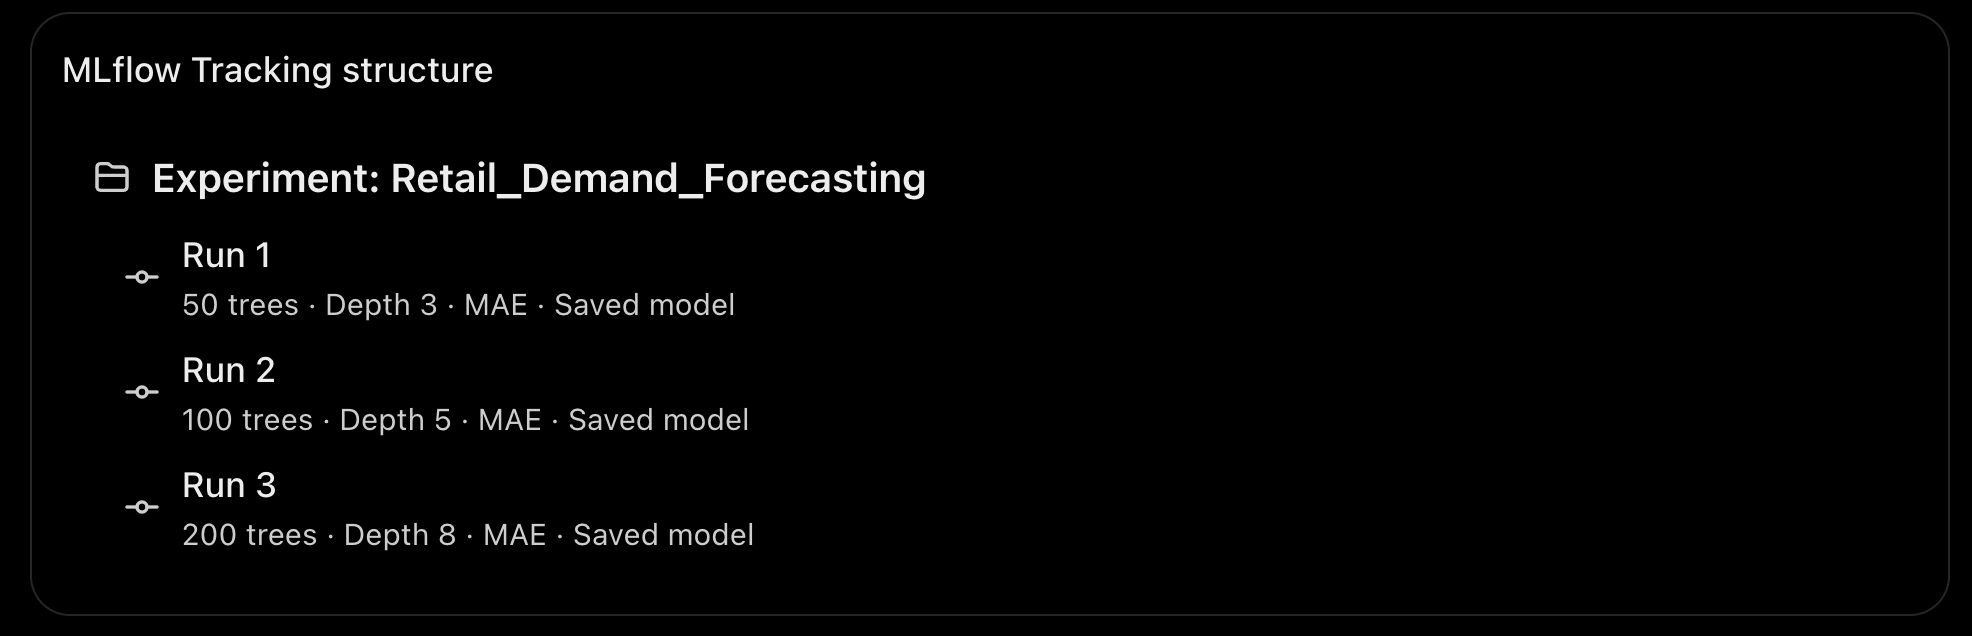

In [17]:
# Install MLflow and launch the dashboard

# MacOS:
# Terminal 1 — Activate the existing project
# cd fde-mlops
# source .venv/bin/activate
# python -m pip install mlflow
# Start MLflow:
# mlflow server --port 5000

# Windows:
# PowerShell Terminal 1 — Activate the existing project
# cd fde-mlops
# .\.venv\Scripts\Activate.ps1
# python -m pip install mlflow
# Start MLflow:
# mlflow server --port 5000
# If PowerShell blocks activation, use Command Prompt and run .venv\Scripts\activate.bat.

# Open your browser:
# http://127.0.0.1:5000

In [18]:
# Extend our existing model with MLflow

# Create one additional file:

# fde-mlops/
# ├── .venv/
# ├── train.py
# ├── experiment.py      ← New file for Topic 3
# └── artifacts/
#     ├── demand_model.joblib
#     └── features.joblib

# Step 1 — Create experiment.py


# import numpy as np
# import pandas as pd
# import mlflow
# import mlflow.sklearn

# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import mean_absolute_error
# from mlflow.models import infer_signature

# # STEP 1: Connect to our local MLflow server
# mlflow.set_tracking_uri("http://127.0.0.1:5000")

# # STEP 2: Create or select the experiment
# mlflow.set_experiment("Retail_Demand_Forecasting")

# # STEP 3: Reuse the same dataset from Topic 2
# rng = np.random.default_rng(42)

# days = np.arange(1, 241)
# day_of_week = (days - 1) % 7
# promotion = ((days % 17) < 3).astype(int)

# sales = (
#     95
#     + 15 * (day_of_week >= 5)
#     + 30 * promotion
#     + rng.normal(0, 5, len(days))
# )

# sales = np.maximum(0, np.rint(sales)).astype(int)

# df = pd.DataFrame({
#     "day": days,
#     "day_of_week": day_of_week,
#     "promotion": promotion,
#     "sales": sales
# })

# df["sales_lag_7"] = df["sales"].shift(7)
# df = df.dropna().copy()

# features = [
#     "day_of_week",
#     "promotion",
#     "sales_lag_7"
# ]

# train = df[df["day"] <= 200]
# test = df[df["day"] > 200]

# X_train = train[features]
# y_train = train["sales"]

# X_test = test[features]
# y_test = test["sales"]

# # STEP 4: Define three model configurations
# configurations = [
#     {"n_estimators": 50, "max_depth": 3},
#     {"n_estimators": 100, "max_depth": 5},
#     {"n_estimators": 200, "max_depth": 8}
# ]

# # STEP 5: Train and track each configuration
# results = []

# for config in configurations:

#     run_name = (
#         f"RF_Trees_{config['n_estimators']}"
#         f"_Depth_{config['max_depth']}"
#     )

#     with mlflow.start_run(run_name=run_name):

#         # Create and train the model
#         model = RandomForestRegressor(
#             **config,
#             random_state=42
#         )

#         model.fit(X_train, y_train)

#         # Generate predictions and evaluate
#         predictions = model.predict(X_test)

#         mae = mean_absolute_error(
#             y_test, predictions
#         )

#         # Record the experiment settings
#         mlflow.log_params(config)

#         # Record the evaluation result
#         mlflow.log_metric("mae", mae)

#         # Add useful descriptive metadata
#         mlflow.set_tag(
#             "use_case", "Retail Demand Forecasting"
#         )

#         # Define the model's input and output schema
#         signature = infer_signature(
#             X_test, predictions
#         )

#         # Save the model in MLflow
#         model_info = mlflow.sklearn.log_model(
#             sk_model=model,
#             name="demand_model",
#             signature=signature,
#             input_example=X_train.head(3)
#         )

#         # Remember the results for comparison
#         results.append({
#             "run_name": run_name,
#             "mae": mae,
#             "model_uri": model_info.model_uri
#         })

#         print(f"{run_name} | MAE: {mae:.3f}")

# # STEP 6: Identify the lowest-error model
# best = min(results, key=lambda x: x["mae"])

# print("\nBEST MODEL")
# print("Run:", best["run_name"])
# print("MAE:", round(best["mae"], 3))
# print("Model URI:", best["model_uri"])


# Step 2 — Execute the experiments
# python experiment.py

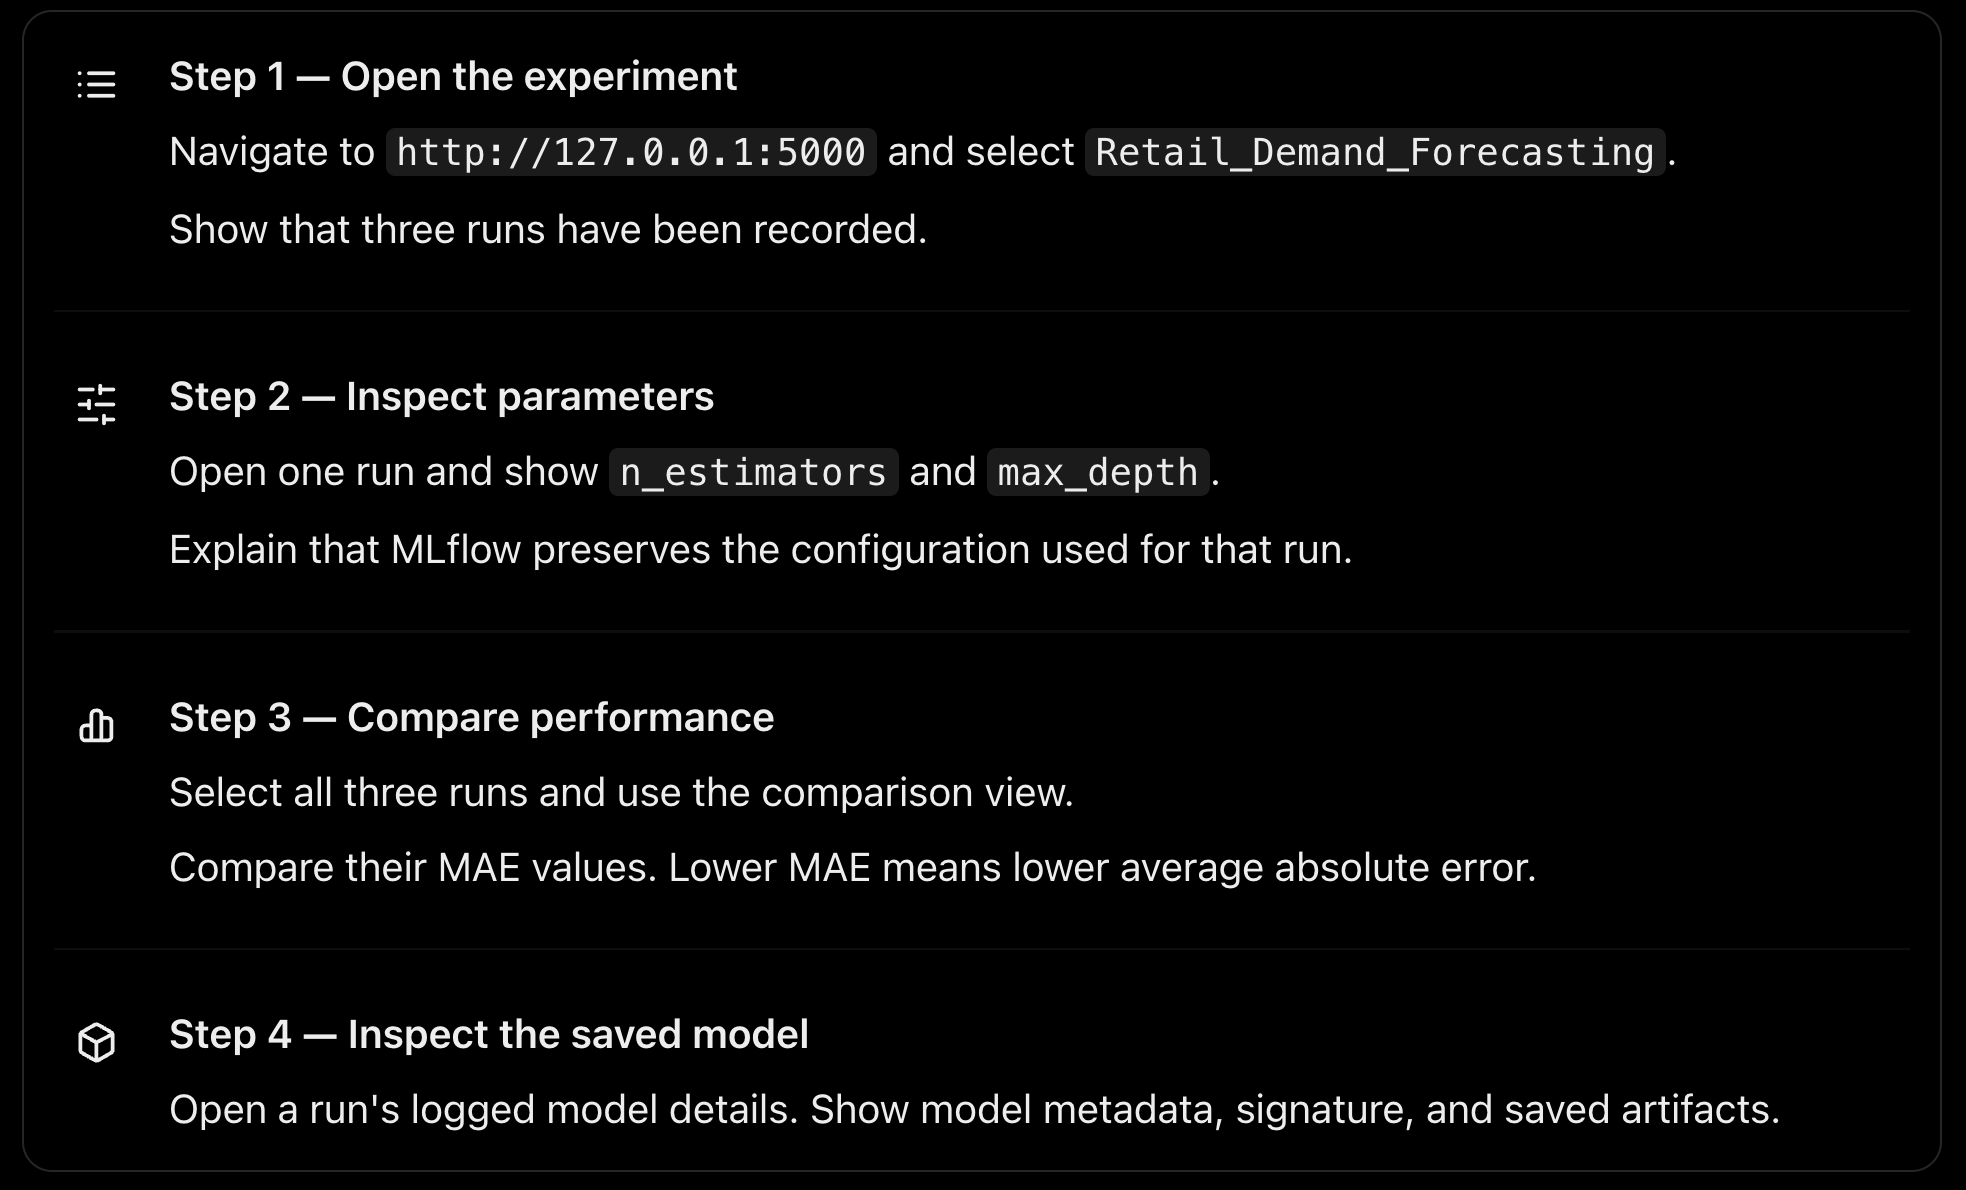

In [19]:
# MCQ 1. What is an MLflow run?
# a. A collection of unrelated datasets
# >b. One tracked execution of model training or evaluation
# c. A production API
# d. A Python virtual environment

# MCQ 2. Which MLflow function should we use to record Mean Absolute Error?
# a. mlflow.log_param()
# b. mlflow.start_run()
# >c. mlflow.log_metric()
# d. mlflow.set_experiment()

# MCQ 3. Which model should we select if the objective is to minimize MAE?
# a. The model with the most trees
# b. The model with the greatest depth
# >c. The model with the lowest measured MAE on a valid comparison
# d. Always the latest trained model

## Topic 4: Model Registry, Model Serving & API Integration with FastAPI

In [20]:
# Topic 4: Model Registry, Model Serving & API Integration with FastAPI

In [21]:
# Why do we need Model Registry and serving?

# In our previous module, we trained three versions of our retail demand forecasting model and compared them using MLflow.

# We now know which model achieved the lowest Mean Absolute Error.

# But imagine our customer tells us:
#     'The model looks good. Now we want our inventory planning application to send a request and receive the predicted demand.'

# Think about that for a moment.
# The inventory application cannot depend on a data scientist manually opening a notebook and executing model.predict() every time.
# We need a mechanism to identify the approved model, load it, and make predictions available to other software systems.

# That's where two important concepts come in.
# 1. Model Registry helps us manage model versions.
# 2. Model Serving makes predictions available to applications.
# Today, we're going to implement both using MLflow and FastAPI."

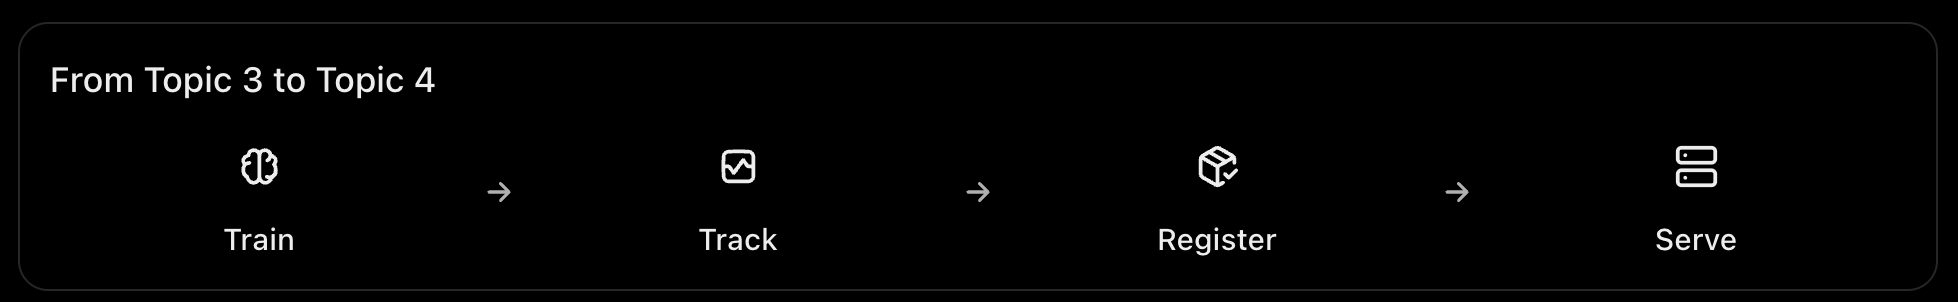

In [22]:
# Understand Model Registry, versions, and aliases

# Model Registry:
# Imagine we've trained ten different machine learning models. We don't want our customer's application to randomly pick one of them.
# We need an organized place where we can register, version, and identify the model selected for use.

# When we register our first model under a name, MLflow creates Version 1. Registering another model under the same name creates a new version.

# We can also assign an alias — a meaningful name that points to a specific model version.

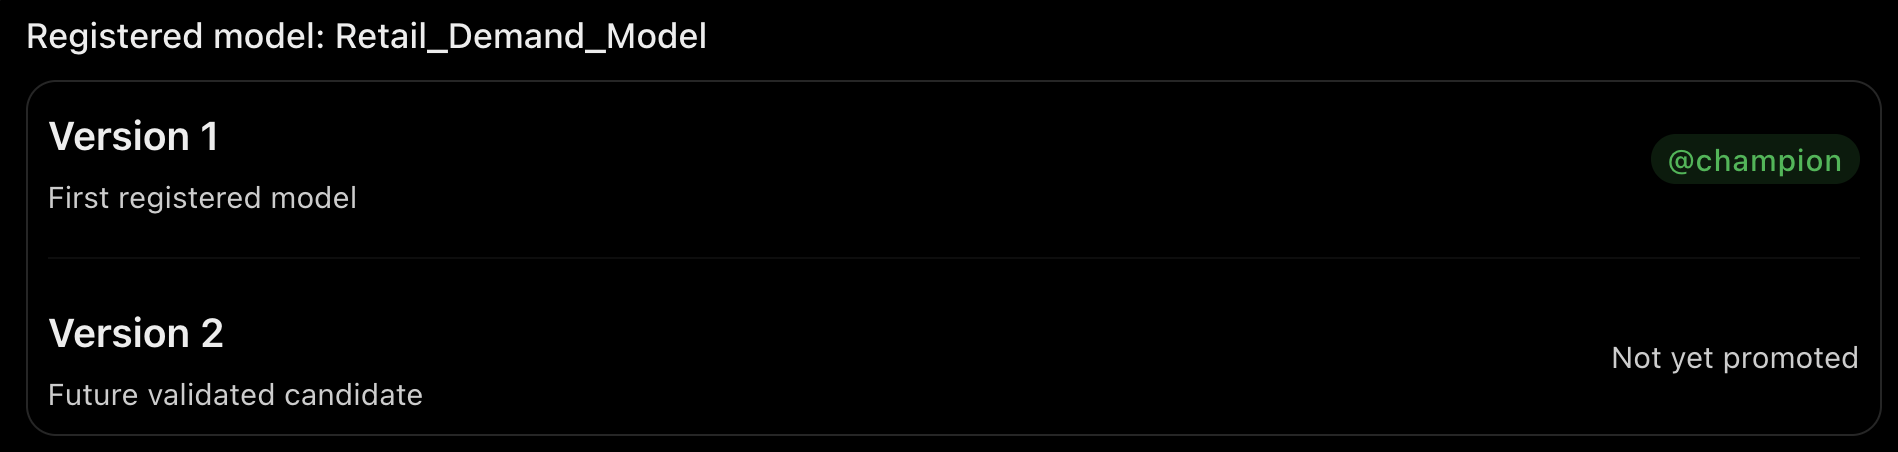

In [23]:
# Show this model URI:
# models:/Retail_Demand_Model@champion

# MLflow supports model versions, aliases, and model lineage through its registry APIs.

In [ ]:
Register the best model from Topic 3

Our MLflow server should still be running on port 5000 from Topic 3.

Step A — Install the remaining dependencies

MacOS:
In a new terminal:
cd fde-mlops
source .venv/bin/activate
python -m pip install fastapi uvicorn

Windows:
In PowerShell:
cd fde-mlops
.\.venv\Scripts\Activate.ps1
python -m pip install fastapi uvicorn
If PowerShell prevents activation, use Command Prompt and .venv\Scripts\activate.bat.

Real-life example: Walmart demand forecasting
- FastAPI: Receives a request like "Predict tomorrow's sales" and returns "125 units."
- Uvicorn: Runs the server so applications can send prediction requests to FastAPI.
Remember: FastAPI creates the API; Uvicorn runs it.

We are installing two new libraries:
- fastapi lets us build an HTTP prediction API.
- uvicorn runs the FastAPI application as an ASGI web server.

Step B — Create register_model.py

fde-mlops/
├── train.py
├── experiment.py
├── register_model.py   ← New
└── artifacts/
    ├── demand_model.joblib
    └── features.joblib

The following program retrieves the best run by MAE, locates the saved MLflow model from that run, and registers it.


import mlflow
from mlflow import MlflowClient

# 1. Connect to the existing MLflow server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

client = MlflowClient()

# 2. Locate the experiment from Topic 3
experiment = mlflow.get_experiment_by_name(
    "Retail_Demand_Forecasting"
)

if experiment is None:
    raise RuntimeError("Run experiment.py first.")

# 3. Find the run with the lowest MAE
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="metrics.mae >= 0",
    order_by=["metrics.mae ASC"],
    max_results=1
)

if runs.empty:
    raise RuntimeError("No evaluated runs found.")

best_run_id = runs.iloc[0]["run_id"]
best_mae = runs.iloc[0]["metrics.mae"]

# 4. Find the logged model belonging to that run
logged_models = mlflow.search_logged_models(
    experiment_ids=[experiment.experiment_id],
    output_format="list"
)

matching_models = [
    model for model in logged_models
    if model.source_run_id == best_run_id
]

if not matching_models:
    raise RuntimeError("No model found for the best run.")

best_model = matching_models[0]

# 5. Register the previously saved model
registered = mlflow.register_model(
    model_uri=f"models:/{best_model.model_id}",
    name="Retail_Demand_Model"
)

# 6. Assign a champion alias
client.set_registered_model_alias(
    name="Retail_Demand_Model",
    alias="champion",
    version=registered.version
)

print("Best run ID:", best_run_id)
print("Best MAE:", round(best_mae, 3))
print("Registered version:", registered.version)
print("Champion alias assigned")


# Step C — Execute
# python register_model.py

# Expected output structure:
# Bes

# Version 1 is expected when the registered model name does not already exist. Re-running the script can create additional versions, so run it once during the live demonstration.


# Step D — Verify in the browser
# Open the MLflow UI:

# http://127.0.0.1:5000

# Navigate to Registered Models, open Retail_Demand_Model, and show its version and champion alias.

# "At this point, our model has moved from an experimental artifact into a versioned, discoverable model asset."

In [25]:
# Understand FastAPI and model serving

# Suppose Walmart's inventory application wants to know how many units of a product might sell tomorrow.

# The application sends three input values to our prediction service.

# Our service loads the approved model, generates a prediction, and returns the result.

# This is called model serving.

# We'll implement it with FastAPI, a Python framework for building APIs.

### Understand the communication flow

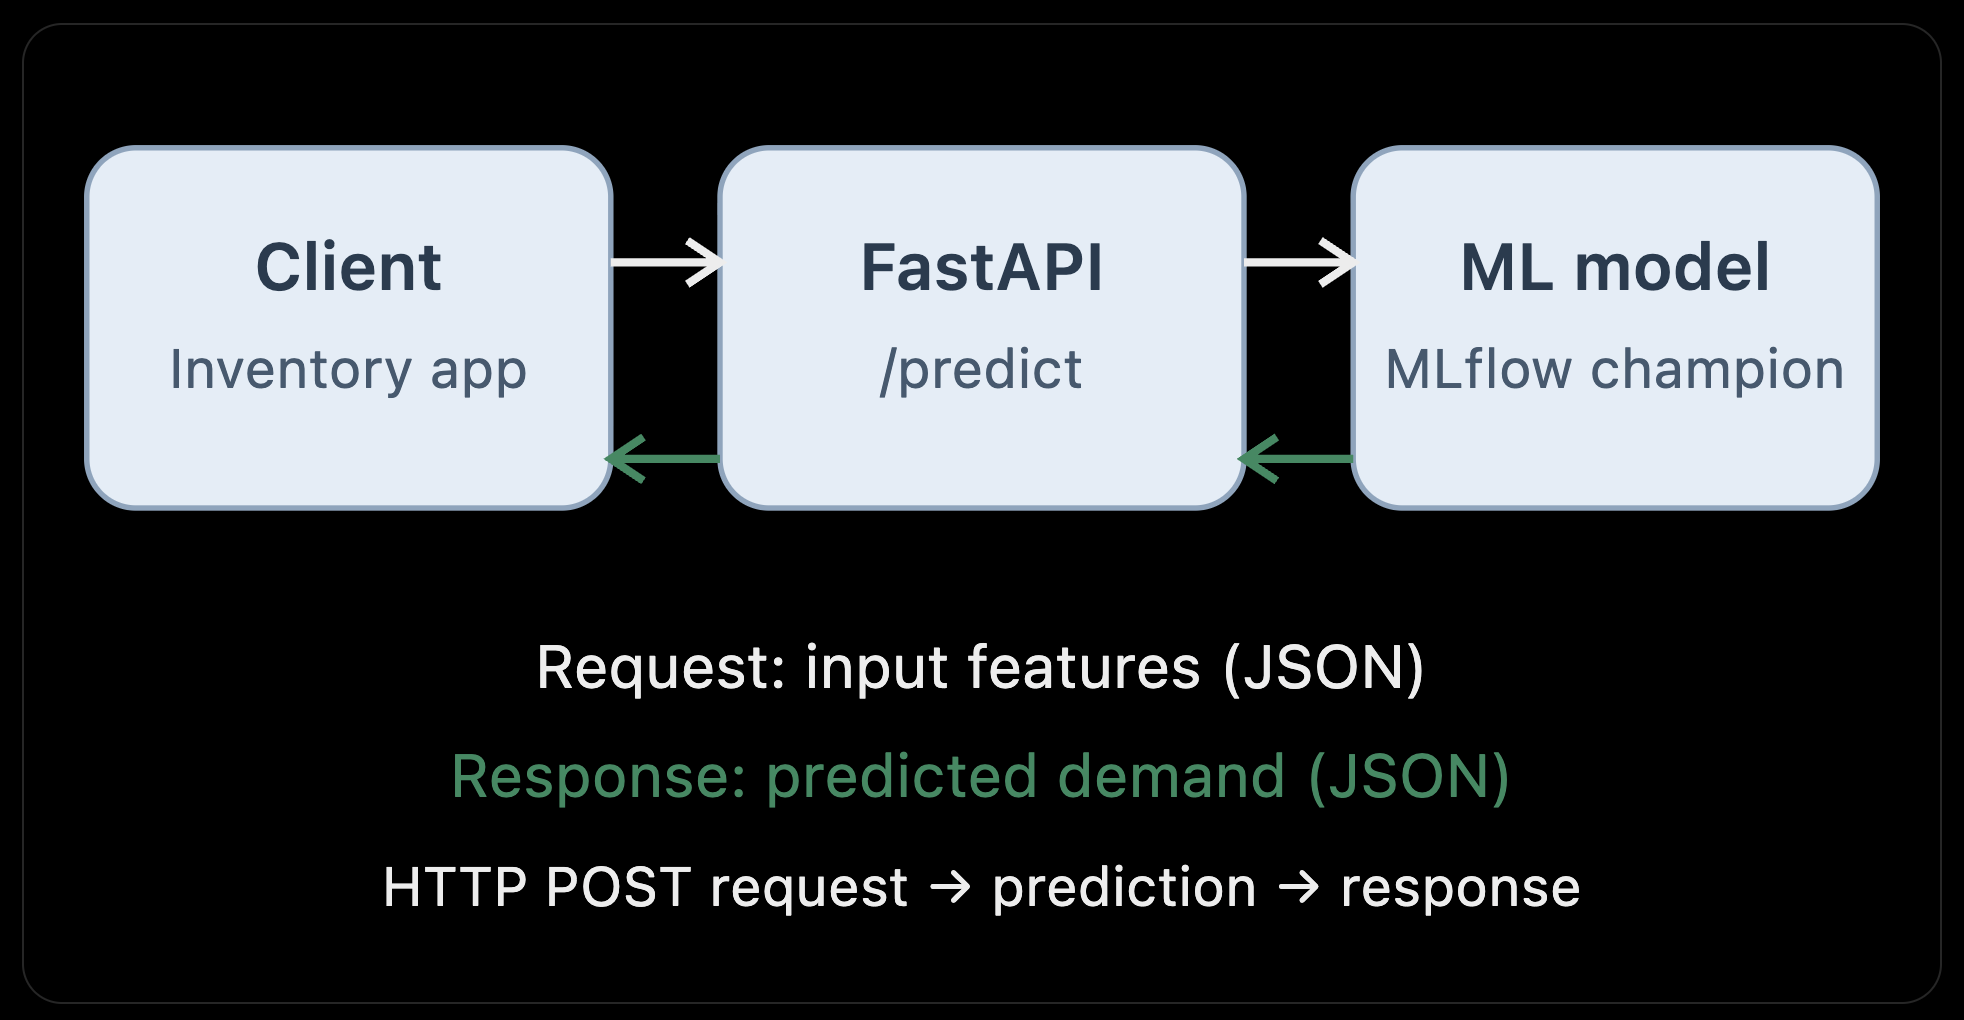

In [26]:
# Introduce four simple terms:

# 1. API: An interface through which software applications communicate

# 2. Endpoint: A specific URL where an API operation is available

# 3. POST: HTTP method commonly used to send prediction inputs

# 4. JSON: A lightweight data format for exchanging information between applications


# FastAPI will not train our model. Its responsibility is to receive inputs, validate them, call the loaded model, and return predictions."
# FastAPI also generates interactive API documentation automatically at /docs.

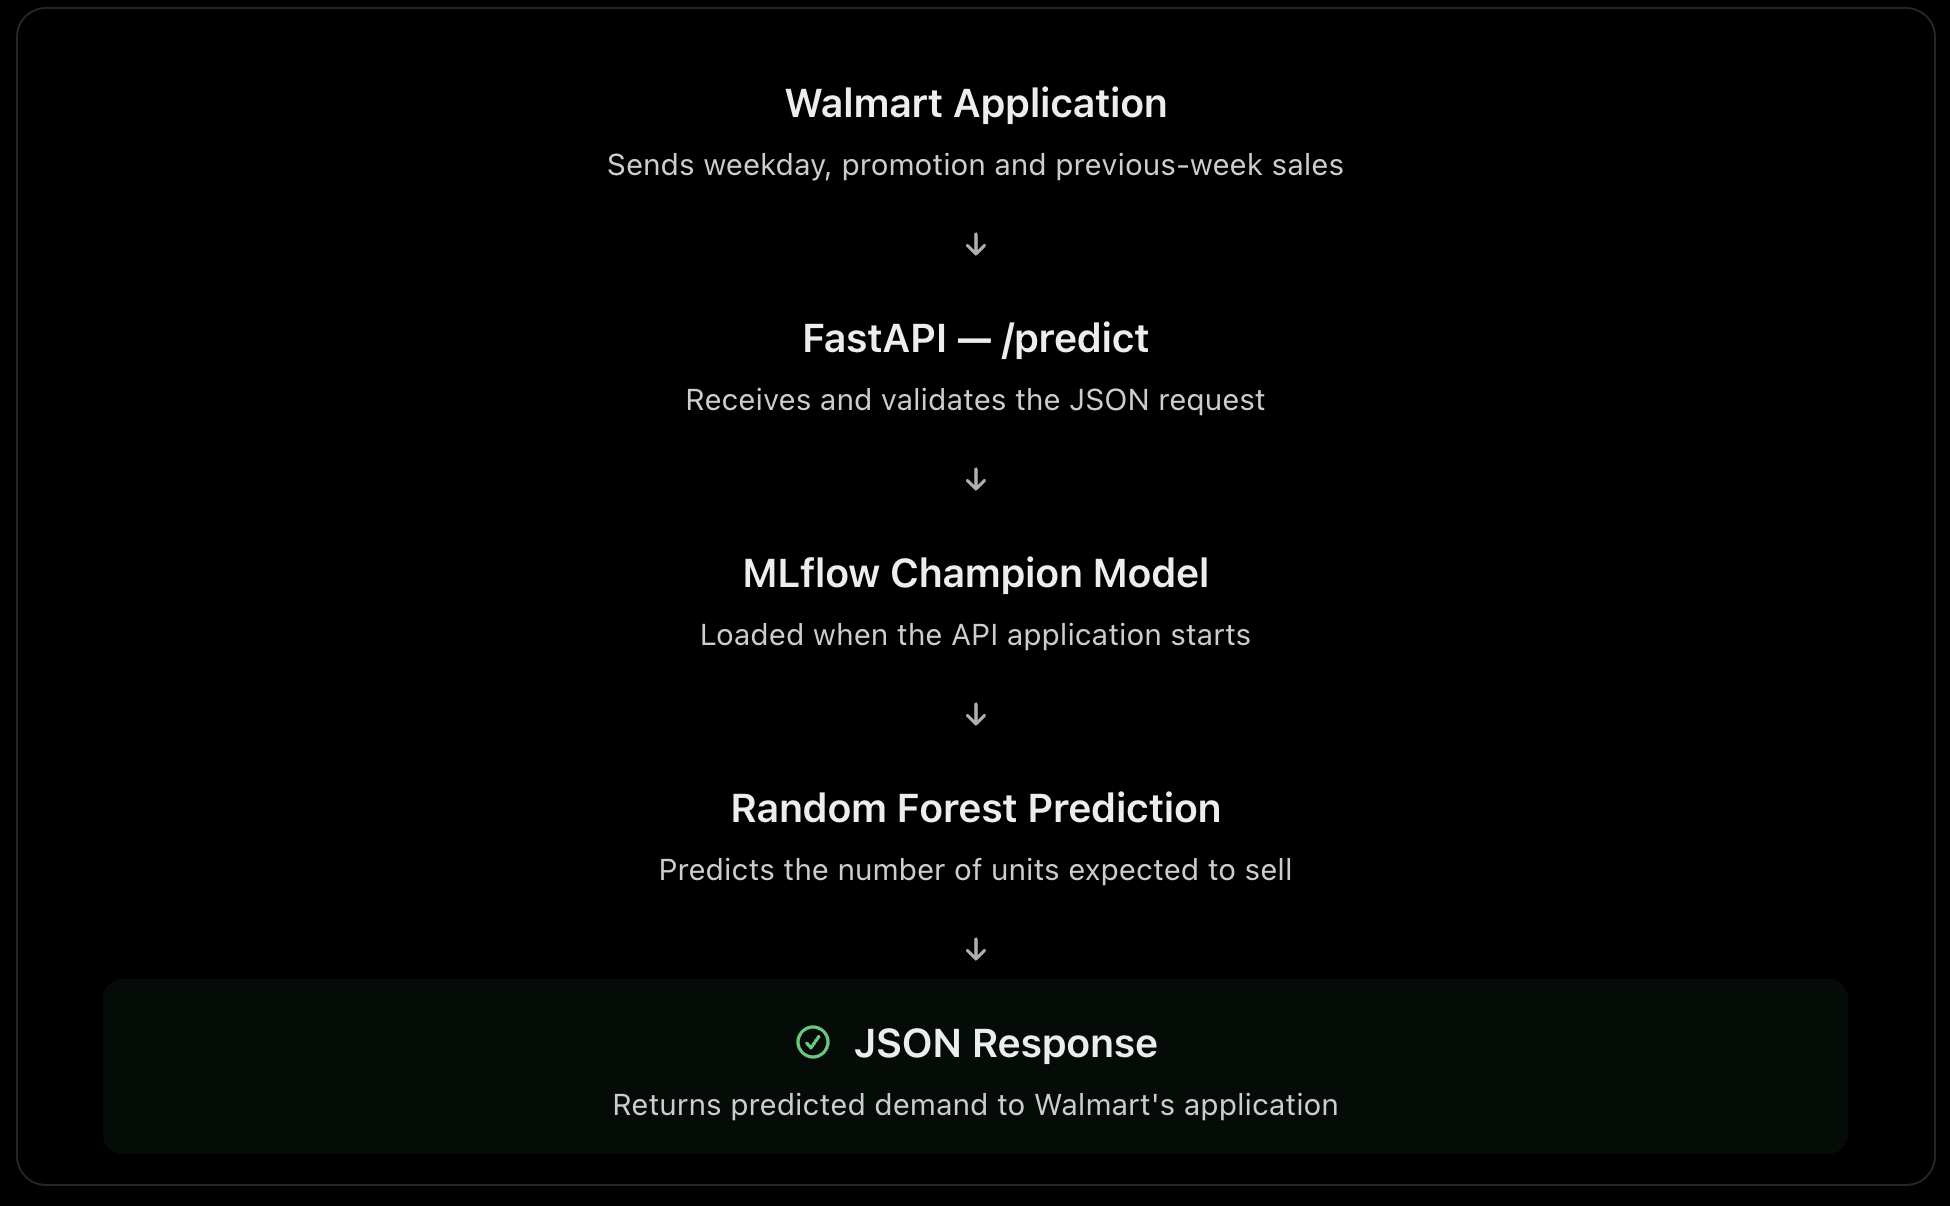

In [27]:
# Build our prediction API

# Create app.py inside the same fde-mlops folder.

# Step A — Write the FastAPI application


# import mlflow
# import mlflow.sklearn
# import pandas as pd

# from fastapi import FastAPI
# from pydantic import BaseModel, Field

# # 1. Connect to the MLflow server
# mlflow.set_tracking_uri("http://127.0.0.1:5000")

# # 2. Load the registered champion model once
# model = mlflow.sklearn.load_model(
#     "models:/Retail_Demand_Model@champion"
# )

# # 3. Create the API application
# app = FastAPI(title="Retail Demand Prediction API")

# # 4. Define the expected input
# class DemandInput(BaseModel):
#     day_of_week: int = Field(ge=0, le=6)
#     promotion: int = Field(ge=0, le=1)
#     sales_lag_7: float = Field(ge=0)

# # 5. Create a health check endpoint
# @app.get("/health")
# def health():
#     return {"status": "ok"}

# # 6. Create a prediction endpoint
# @app.post("/predict")
# def predict(data: DemandInput):

#     # Convert JSON input into model features
#     features = pd.DataFrame([{
#         "day_of_week": data.day_of_week,
#         "promotion": data.promotion,
#         "sales_lag_7": data.sales_lag_7
#     }])

#     # Generate prediction
#     prediction = model.predict(features)[0]

#     # Return JSON response
#     return {
#         "predicted_demand": round(
#             max(0, float(prediction)), 2
#         ),
#         "unit": "units"
#     }


# How to run the API
# Assuming the code is saved in app.py:

# python -m uvicorn app:app --reload

# Then open:
# - Health check: http://127.0.0.1:8000/health
# - Interactive API testing: http://127.0.0.1:8000/docs
# The /docs page lets participants test predictions without writing additional Python code.

In [28]:
# MCQ 1. What is the primary purpose of the MLflow Model Registry?
# a. Train machine learning models automatically
# >b. Manage model versions, metadata and aliases
# c. Generate business dashboards
# d. Replace Python

# MCQ 2. What does the alias @champion represent?
# a. The model with the highest training accuracy, automatically
# >b. A named reference to a selected registered model version
# c. The first model ever trained
# d. A Git branch

# MCQ 3. Which HTTP method are we using to submit prediction inputs to FastAPI?
# a. GET
# b. DELETE
# >c. POST
# d. PUT

In [29]:
# fde-mlops/
# ├── .venv/
# ├── train.py
# ├── experiment.py
# ├── register_model.py
# ├── app.py
# └── artifacts/
#     ├── demand_model.joblib
#     └── features.joblib

## Topic 5: ML Pipelines — Automating Training, Evaluation & Model Management

In [31]:
# Topic 5: ML Pipelines — Automating Training, Evaluation & Model Management